In [6]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, random_split

In [ ]:

full = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
train_ds, valid_ds = random_split(full, [50_000, 10_000], generator=torch.Generator().manual_seed(0))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
validation_loader = DataLoader(valid_ds, batch_size=64)

100%|██████████| 26.4M/26.4M [00:09<00:00, 2.81MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 186kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [4]:
xb, yb = next(iter(train_loader))

In [5]:
print(xb.shape, yb.shape, xb.min(), xb.max(), yb[:10])

torch.Size([64, 1, 28, 28]) torch.Size([64]) tensor(0.) tensor(1.) tensor([4, 6, 1, 7, 9, 8, 1, 6, 6, 2])


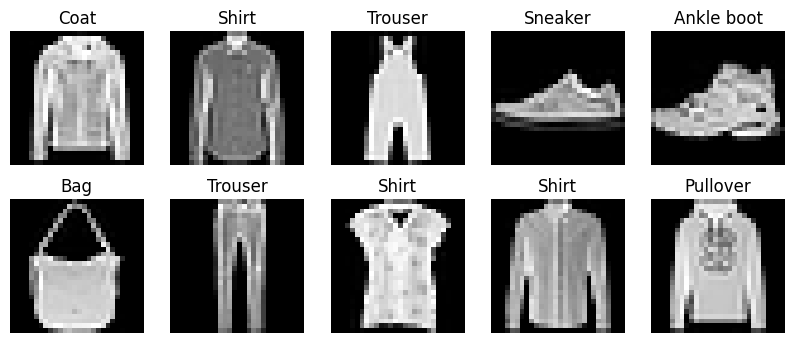

In [8]:
import matplotlib.pyplot as plt
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(2, 5, figsize=(10,4))
for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.show()

In [11]:
from torch import nn

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10)
)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=10, bias=True)
)


In [12]:
out = model(xb)
print(out.shape)          # expect: torch.Size([64, 10])
print(out[0])             # 10 raw scores ("logits") for the first image

torch.Size([64, 10])
tensor([ 0.2314,  0.1205, -0.1254,  0.0094, -0.0831,  0.1775, -0.0431,  0.1767,
         0.0365, -0.2620], grad_fn=<SelectBackward0>)


In [13]:
n_params = sum(p.numel() for p in model.parameters())
print(n_params)           # my guess by hand: ___[64, 1, 28, 28]

203530


In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
print(device, next(model.parameters()).device)

cuda cuda:0


In [15]:
import time

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader, loss_fn, opt, device):
    model.train()
    model = model.to(device)
    total_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        opt.step()

        total_loss +=loss.item()
    return total_loss/len(loader)



In [16]:
def evaluate(model, loader, loss_fn, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += yb.size(0)

    return total_loss/len(loader), correct/total



In [17]:
train_losses, val_losses = [], []
for epoch in range(1, 11):
    t0 = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, loss_fn, opt, device)
    val_loss, val_acc = evaluate(model, validation_loader, loss_fn, device)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | "
          f"acc {val_acc:.2%} | {time.perf_counter() - t0:.1f}s")

epoch  1 | train 0.5433 | val 0.4637 | acc 82.25% | 4.6s
epoch  2 | train 0.3949 | val 0.3874 | acc 85.47% | 3.7s
epoch  3 | train 0.3521 | val 0.3442 | acc 87.45% | 5.1s
epoch  4 | train 0.3266 | val 0.3626 | acc 86.85% | 4.6s
epoch  5 | train 0.3059 | val 0.3300 | acc 87.82% | 4.7s
epoch  6 | train 0.2888 | val 0.3315 | acc 87.82% | 3.8s
epoch  7 | train 0.2768 | val 0.3254 | acc 87.84% | 4.4s
epoch  8 | train 0.2642 | val 0.3073 | acc 88.37% | 4.4s
epoch  9 | train 0.2537 | val 0.3076 | acc 88.48% | 4.6s
epoch 10 | train 0.2449 | val 0.2937 | acc 89.16% | 4.6s


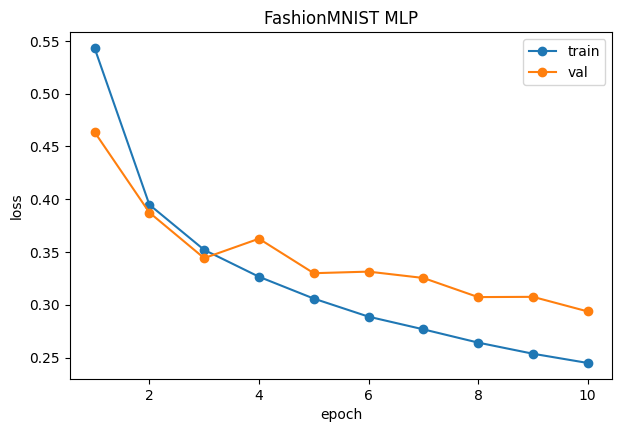

In [19]:
import os
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 11), train_losses, marker="o", label="train")
plt.plot(range(1, 11), val_losses, marker="o", label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("FashionMNIST MLP")
plt.show()

os.makedirs("checkpoints", exist_ok=True)
torch.save(model.state_dict(), "checkpoints/mlp.pt")

In [1]:
import torch
yb   = torch.tensor([9, 2, 2, 6, 2, 0])
pred = torch.tensor([9, 2, 4, 6, 2, 6])

mask = yb == 2
print(mask)                     # which images are pullovers?
print(mask.sum())               # how many?
print(pred[mask])               # model's guesses for those
print(pred[mask] == 2)          # which guesses were right?
print((pred[mask] == 2).sum())  # how many right?

tensor([False,  True,  True, False,  True, False])
tensor(3)
tensor([2, 4, 2])
tensor([ True, False,  True])
tensor(2)
